In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Import Modules

In [2]:
import pandas as pd
import numpy as np
from math import sqrt
from numpy import mean
from numpy.random import rand
import matplotlib.pyplot as plt

# Read Data

In [3]:
df = pd.read_csv('/content/drive/MyDrive/CS190-3P/Fruit-Vegetable Dataset.csv')

In [4]:
df.head()

,Record No,Color,Shape,Texture,Taste,Class
0,1,Yellow,Elongated,Rough,Sweet,Fruit
1,2,Red,Rounded,Smooth,Sweet,Fruit
2,3,Green,Semi-Elongated,Rough,Bland,Vegetable
3,4,Orange,Rounded,Smooth,Sweet,Fruit
4,5,Green,Elongated,Smooth,Bland,Vegetable


# Data Transformation

In [5]:
df = df.drop('Record No', axis=1)

In [6]:
df.head()

,Color,Shape,Texture,Taste,Class
0,Yellow,Elongated,Rough,Sweet,Fruit
1,Red,Rounded,Smooth,Sweet,Fruit
2,Green,Semi-Elongated,Rough,Bland,Vegetable
3,Orange,Rounded,Smooth,Sweet,Fruit
4,Green,Elongated,Smooth,Bland,Vegetable


In [7]:
print(df.columns)

Index(['Color', 'Shape', 'Texture', 'Taste', 'Class'], dtype='object')


In [8]:
df = pd.get_dummies(df, columns=['Color', 'Shape', 'Texture', 'Taste', 'Class'])

In [9]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Color_Green           25 non-null     bool 
 1   Color_Orange          25 non-null     bool 
 2   Color_Red             25 non-null     bool 
 3   Color_Yellow          25 non-null     bool 
 4   Shape_Elongated       25 non-null     bool 
 5   Shape_Rounded         25 non-null     bool 
 6   Shape_Scattered       25 non-null     bool 
 7   Shape_Semi-Elongated  25 non-null     bool 
 8   Texture_Rough         25 non-null     bool 
 9   Texture_Smooth        25 non-null     bool 
 10  Taste_Bland           25 non-null     bool 
 11  Taste_Sour            25 non-null     bool 
 12  Taste_Sweet           25 non-null     bool 
 13  Class_Fruit           25 non-null     bool 
 14  Class_Vegetable       25 non-null     bool 
dtypes: bool(15)
memory usage: 507.0 bytes
None


In [10]:
df.head()

,Color_Green,Color_Orange,Color_Red,Color_Yellow,Shape_Elongated,Shape_Rounded,Shape_Scattered,Shape_Semi-Elongated,Texture_Rough,Texture_Smooth,Taste_Bland,Taste_Sour,Taste_Sweet,Class_Fruit,Class_Vegetable
0,False,False,False,True,True,False,False,False,True,False,False,False,True,True,False
1,False,False,True,False,False,True,False,False,False,True,False,False,True,True,False
2,True,False,False,False,False,False,False,True,True,False,True,False,False,False,True
3,False,True,False,False,False,True,False,False,False,True,False,False,True,True,False
4,True,False,False,False,True,False,False,False,False,True,True,False,False,False,True


In [11]:
train_input_columns = [
    'Color_Green', 'Color_Orange', 'Color_Red', 'Color_Yellow',
    'Shape_Elongated', 'Shape_Rounded', 'Shape_Scattered', 'Shape_Semi-Elongated',
    'Texture_Rough', 'Texture_Smooth',
    'Taste_Bland', 'Taste_Sour', 'Taste_Sweet'
]

train_output_columns = ["Class_Fruit", "Class_Vegetable"]

training_inputs = df[train_input_columns].astype(int).to_numpy()
training_outputs = df[train_output_columns].astype(int).to_numpy()

print(training_inputs)
print(training_outputs)

[[0 0 0 1 1 0 0 0 1 0 0 0 1]
 [0 0 1 0 0 1 0 0 0 1 0 0 1]
 [1 0 0 0 0 0 0 1 1 0 1 0 0]
 [0 1 0 0 0 1 0 0 0 1 0 0 1]
 [1 0 0 0 1 0 0 0 0 1 1 0 0]
 [1 0 0 0 1 0 0 0 0 1 0 0 1]
 [0 0 0 1 0 0 1 0 1 0 1 0 0]
 [0 0 0 1 1 0 0 0 1 0 1 0 0]
 [0 1 0 0 0 1 0 0 1 0 1 0 0]
 [1 0 0 0 0 1 0 0 0 1 0 1 0]
 [1 0 0 0 0 0 1 0 0 1 0 1 0]
 [0 0 1 0 0 0 1 0 0 1 0 1 0]
 [0 0 1 0 0 0 0 1 1 0 1 0 0]
 [1 0 0 0 0 1 0 0 0 1 1 0 0]
 [1 0 0 0 0 0 0 1 0 1 0 0 1]
 [1 0 0 0 0 1 0 0 1 0 0 1 0]
 [0 0 1 0 0 1 0 0 1 0 0 0 1]
 [1 0 0 0 0 1 0 0 1 0 0 1 0]
 [0 0 1 0 0 1 0 0 0 1 0 1 0]
 [0 0 0 1 1 0 0 0 0 1 0 1 0]
 [1 0 0 0 0 1 0 0 1 0 1 0 0]
 [0 0 0 1 1 0 0 0 1 0 0 0 1]
 [1 0 0 0 1 0 0 0 0 1 1 0 0]
 [1 0 0 0 1 0 0 0 1 0 1 0 0]
 [1 0 0 0 0 1 0 0 0 1 1 0 0]]
[[1 0]
 [1 0]
 [0 1]
 [1 0]
 [0 1]
 [1 0]
 [0 1]
 [1 0]
 [0 1]
 [1 0]
 [0 1]
 [1 0]
 [0 1]
 [0 1]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [1 0]
 [0 1]
 [0 1]
 [0 1]
 [0 1]
 [0 1]]


# Activation Function

In [12]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# New Acitivty

In [13]:
def forward_step_by_step(inputs, W1, W2, W3, init_method):
    """Perform one forward pass and print each step."""
    print(f"\nForward Propagation Steps for {init_method} Initialization:")

    # Step 1: Input to first hidden layer
    print("\nStep 1: Input to First Hidden Layer")
    print("Input shape:", inputs.shape)
    print("W1 shape:", W1.shape)
    hidden1_input = np.dot(inputs, W1)
    print("Hidden1 input (after dot product with W1):\n", hidden1_input[:2])
    hidden1_output = sigmoid(hidden1_input)
    print("Hidden1 output (after sigmoid):\n", hidden1_output[:2])

    # Step 2: First hidden layer to second hidden layer
    print("\nStep 2: First Hidden Layer to Second Hidden Layer")
    print("Hidden1 output shape:", hidden1_output.shape)
    print("W2 shape:", W2.shape)
    hidden2_input = np.dot(hidden1_output, W2)
    print("Hidden2 input (after dot product with W2):\n", hidden2_input[:2])
    hidden2_output = sigmoid(hidden2_input)
    print("Hidden2 output (after sigmoid):\n", hidden2_output[:2])

    # Step 3: Second hidden layer to output layer
    print("\nStep 3: Second Hidden Layer to Output Layer")
    print("Hidden2 output shape:", hidden2_output.shape)
    print("W3 shape:", W3.shape)
    final_input = np.dot(hidden2_output, W3)
    print("Final input (after dot product with W3):\n", final_input[:2])
    final_output = sigmoid(final_input)
    print("Final output (after sigmoid):\n", final_output[:2])

    return final_output

def train_weights_multi_layer(training_inputs, training_outputs, W1, W2, W3, epochs=1000, learning_rate=0.1, init_method='xavier'):
    epoch = np.array([])
    total_error = np.array([])
    mse_history = np.array([])

    # Print forward propagation steps for the first iteration
    forward_step_by_step(training_inputs, W1, W2, W3, init_method)

    for iteration in range(epochs):
        # Forward propagation
        layer1 = sigmoid(np.dot(training_inputs, W1))
        layer2 = sigmoid(np.dot(layer1, W2))
        outputs = sigmoid(np.dot(layer2, W3))

        # Error calculation
        error = training_outputs - outputs
        total_error = np.append(total_error, np.sum(np.abs(error)))
        mse = np.mean(np.square(error))
        mse_history = np.append(mse_history, mse)

        # Backpropagation
        delta3 = error * sigmoid_derivative(outputs)
        delta2 = np.dot(delta3, W3.T) * sigmoid_derivative(layer2)
        delta1 = np.dot(delta2, W2.T) * sigmoid_derivative(layer1)

        # Update weights
        W3 += learning_rate * np.dot(layer2.T, delta3)
        W2 += learning_rate * np.dot(layer1.T, delta2)
        W1 += learning_rate * np.dot(training_inputs.T, delta1)

        # Track current epoch
        epoch = np.append(epoch, iteration)

    return W1, W2, W3, epoch, total_error, mse_history

# Data setup
train_input_columns = [
    'Color_Green', 'Color_Orange', 'Color_Red', 'Color_Yellow',
    'Shape_Elongated', 'Shape_Rounded', 'Shape_Scattered', 'Shape_Semi-Elongated',
    'Texture_Rough', 'Texture_Smooth',
    'Taste_Bland', 'Taste_Sour', 'Taste_Sweet'
]
train_output_columns = ["Class_Fruit", "Class_Vegetable"]

# Assuming df is your DataFrame
training_inputs = df[train_input_columns].astype(int).to_numpy()
training_outputs = df[train_output_columns].astype(int).to_numpy()

n_features = training_inputs.shape[1]  # 13
n_outputs = training_outputs.shape[1]  # 2
hidden1_size = 4  # First hidden layer size
hidden2_size = 4   # Second hidden layer size

# Initialize weights for different methods
# Generic initialization
W1_generic = 2 * np.random.random((n_features, hidden1_size)) - 1
W2_generic = 2 * np.random.random((hidden1_size, hidden2_size)) - 1
W3_generic = 2 * np.random.random((hidden2_size, n_outputs)) - 1

# Heuristic initialization
W1_heuristic = np.random.uniform(-0.3, 0.3, (n_features, hidden1_size))
W2_heuristic = np.random.uniform(-0.3, 0.3, (hidden1_size, hidden2_size))
W3_heuristic = np.random.uniform(-0.3, 0.3, (hidden2_size, n_outputs))

# Xavier initialization
lower1, upper1 = -(1.0 / sqrt(n_features)), (1.0 / sqrt(n_features))
lower2, upper2 = -(1.0 / sqrt(hidden1_size)), (1.0 / sqrt(hidden1_size))
lower3, upper3 = -(1.0 / sqrt(hidden2_size)), (1.0 / sqrt(hidden2_size))
W1_xavier = np.random.uniform(lower1, upper1, (n_features, hidden1_size))
W2_xavier = np.random.uniform(lower2, upper2, (hidden1_size, hidden2_size))
W3_xavier = np.random.uniform(lower3, upper3, (hidden2_size, n_outputs))

# Train with different weight initializations
W1_g, W2_g, W3_g, epoch_g, error_g, mse_g = train_weights_multi_layer(
    training_inputs, training_outputs, W1_generic, W2_generic, W3_generic,
    init_method='generic'
)

W1_h, W2_h, W3_h, epoch_h, error_h, mse_h = train_weights_multi_layer(
    training_inputs, training_outputs, W1_heuristic, W2_heuristic, W3_heuristic,
    init_method='heuristic'
)

W1_x, W2_x, W3_x, epoch_x, error_x, mse_x = train_weights_multi_layer(
    training_inputs, training_outputs, W1_xavier, W2_xavier, W3_xavier,
    init_method='xavier'
)


Forward Propagation Steps for generic Initialization:

Step 1: Input to First Hidden Layer
Input shape: (25, 13)
W1 shape: (13, 4)
Hidden1 input (after dot product with W1):
 [[-1.43845617 -0.15660678  1.54946872 -1.88891022]
 [-0.57004248  0.31169596  2.71362917 -1.83432579]]
Hidden1 output (after sigmoid):
 [[0.19178453 0.46092813 0.82483699 0.13136878]
 [0.36122702 0.57729917 0.9378261  0.13772375]]

Step 2: First Hidden Layer to Second Hidden Layer
Hidden1 output shape: (25, 4)
W2 shape: (4, 4)
Hidden2 input (after dot product with W2):
 [[ 0.32682088  0.77062841 -0.67813117  0.55831438]
 [ 0.25933485  1.03489514 -0.76820889  0.6747032 ]]
Hidden2 output (after sigmoid):
 [[0.58098565 0.68365681 0.33667853 0.63606243]
 [0.56447278 0.73786382 0.31686669 0.66255548]]

Step 3: Second Hidden Layer to Output Layer
Hidden2 output shape: (25, 4)
W3 shape: (4, 2)
Final input (after dot product with W3):
 [[-0.05847056 -0.07124901]
 [-0.02826794 -0.06291682]]
Final output (after sigmoid):
 

In [14]:
# Print Mean Squared Error for each method
print("\nMean Squared Error (Generic Initialization):")
print(f"Final MSE: {mse_g[-1]:.6f}")
print(f"Average MSE across epochs: {np.mean(mse_g):.6f}")
print("\nMean Squared Error (Heuristic Initialization):")
print(f"Final MSE: {mse_h[-1]:.6f}")
print(f"Average MSE across epochs: {np.mean(mse_h):.6f}")
print("\nMean Squared Error (Xavier Initialization):")
print(f"Final MSE: {mse_x[-1]:.6f}")
print(f"Average MSE across epochs: {np.mean(mse_x):.6f}")


Mean Squared Error (Generic Initialization):
Final MSE: 0.020769
Average MSE across epochs: 0.054680

Mean Squared Error (Heuristic Initialization):
Final MSE: 0.058512
Average MSE across epochs: 0.135203

Mean Squared Error (Xavier Initialization):
Final MSE: 0.057879
Average MSE across epochs: 0.089201


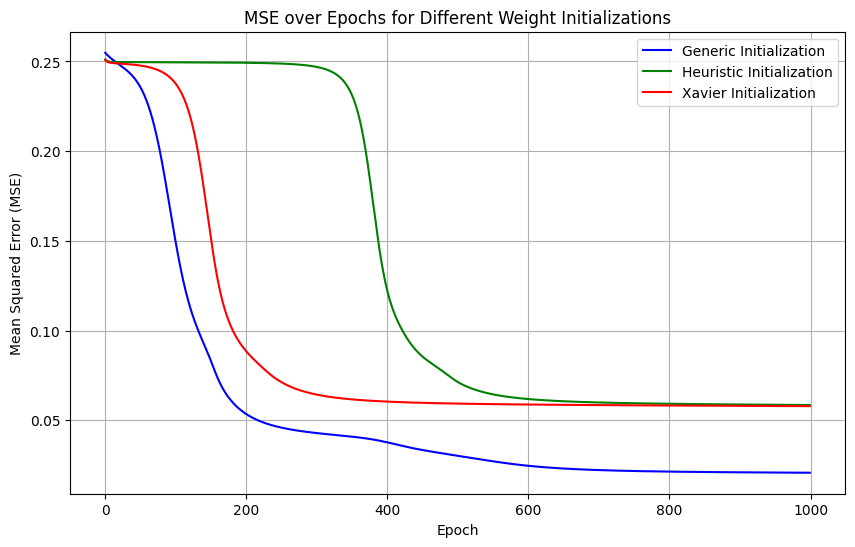

In [15]:
plt.figure(figsize=(10, 6))
plt.plot(epoch_g, mse_g, label='Generic Initialization', color='blue')
plt.plot(epoch_g, mse_h, label='Heuristic Initialization', color='green')
plt.plot(epoch_g, mse_x, label='Xavier Initialization', color='red')

plt.title('MSE over Epochs for Different Weight Initializations')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error (MSE)')
plt.grid(True)
plt.legend()

# Previous Activity

# Weight Function

In [16]:
def train_weights(training_inputs, training_outputs, weights, epochs=100):
    epoch = np.array([])
    total_error = np.array([])
    mse_history = np.array([])

    for iteration in range(epochs):
        input_layer = training_inputs

        # Feedforward
        outputs = sigmoid(np.dot(input_layer, weights))

        # Error calculation
        error = training_outputs - outputs
        total_error = np.append(total_error, np.sum(np.abs(error)))
        mse = np.mean(np.square(error))
        mse_history = np.append(mse_history, mse)

        # Backpropagation
        adjustments = error * sigmoid_derivative(outputs)
        weights += np.dot(input_layer.T, adjustments)

        # Track current epoch
        epoch = np.append(epoch, iteration)

    return weights, epoch, total_error, mse_history


# Xavier Weight

In [17]:
n_features = training_inputs.shape[1]
n_outputs = training_outputs.shape[1]

print("n_features", n_features)
print("n_outputs", n_outputs)

# Xavier weight initialization
lower, upper = -(1.0 / sqrt(n_features)), (1.0 / sqrt(n_features))
numbers = np.random.rand(n_features * n_outputs)
weights = lower + numbers * (upper - lower)
xavier_weights = weights.reshape(n_features, n_outputs)

print("Initial Xavier weights:\n", xavier_weights)

# Train
xavier_weights, x_epoch, xavier_total_error, xavier_mse_history = train_weights(
    training_inputs, training_outputs, xavier_weights, epochs=100
)

# After training
print("Trained weights after training:")
print(xavier_weights)

n_features 13
n_outputs 2
Initial Xavier weights:
 [[ 0.1312656   0.21334274]
 [ 0.09110928  0.01221441]
 [-0.00587027 -0.05038812]
 [ 0.18870431  0.10796756]
 [ 0.10757045 -0.08178968]
 [ 0.11157525 -0.07337129]
 [-0.25196066 -0.08722095]
 [ 0.25914528 -0.21237043]
 [ 0.27623109  0.17557043]
 [-0.19143052  0.07535612]
 [ 0.1418453   0.22308815]
 [ 0.05362109 -0.0922783 ]
 [ 0.0455097  -0.16445555]]
Trained weights after training:
[[-2.10868847  2.20167495]
 [-0.88484823  1.00318217]
 [ 1.41169255 -1.32404247]
 [ 3.28893729 -3.1647305 ]
 [ 2.43171856 -2.55845353]
 [ 1.73277988 -1.86170579]
 [-2.77951367  2.6329114 ]
 [ 0.14322976 -0.23455688]
 [ 0.62026138 -0.59680149]
 [ 0.7664234  -0.71932441]
 [-4.26048234  4.24467031]
 [ 2.45904225 -2.45042893]
 [ 3.34430038 -3.39493954]]


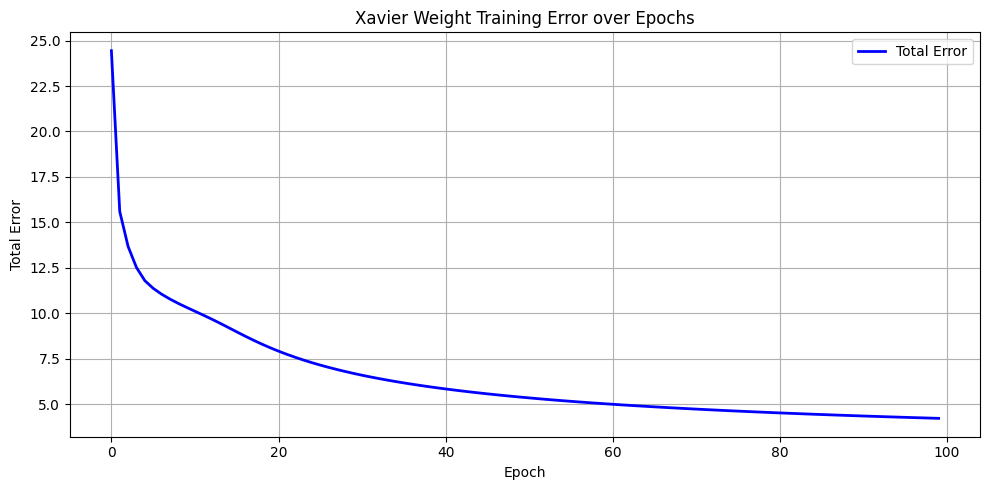

In [18]:
plt.figure(figsize=(10, 5))
plt.plot(x_epoch, xavier_total_error, label="Total Error", color="blue", linewidth=2)

plt.title("Xavier Weight Training Error over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Total Error")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# Apple feature vector
test_apple = np.array([0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1])

# Calculate prediction using the trained weights
prediction_xavier = sigmoid(np.dot(test_apple, xavier_weights))

print("Prediction probabilities for apple input:")
print(prediction_xavier)

print("Output 1: %.4f, Output 2: %.4f" % (prediction_xavier[0], prediction_xavier[1]))

Prediction probabilities for apple input:
[9.99294005e-01 6.75074486e-04]
Output 1: 0.9993, Output 2: 0.0007


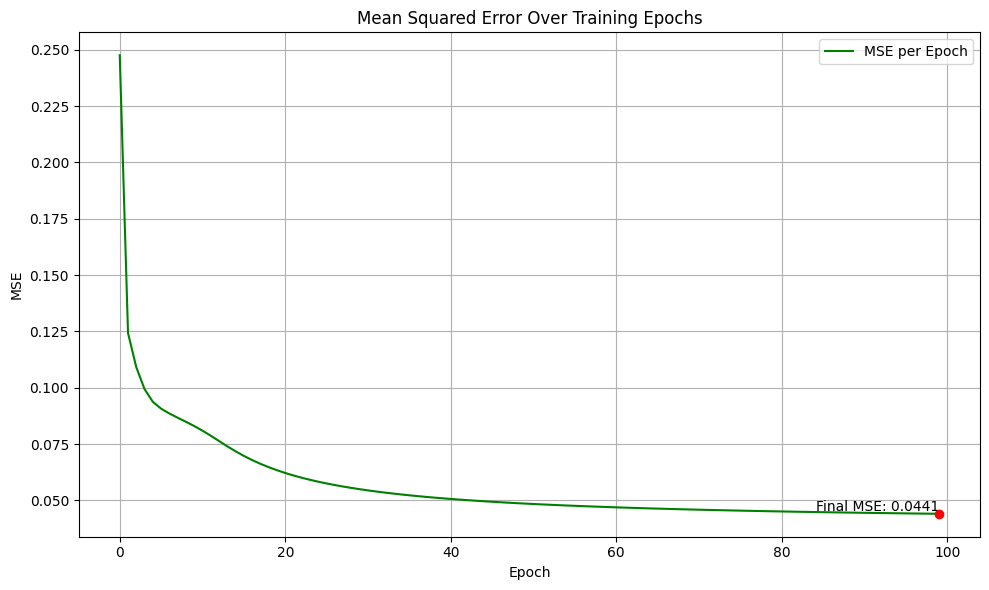

In [20]:
plt.figure(figsize=(10, 6))
plt.plot(x_epoch, xavier_mse_history, label='MSE per Epoch', color='green')

# Highlight the final MSE
plt.scatter(x_epoch[-1], xavier_mse_history[-1], color='red', zorder=5)
plt.text(x_epoch[-1], xavier_mse_history[-1], f'Final MSE: {xavier_mse_history[-1]:.4f}',
         verticalalignment='bottom', horizontalalignment='right')

plt.title('Mean Squared Error Over Training Epochs')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
# Final predictions
final_output_x = sigmoid(np.dot(training_inputs, xavier_weights))

# Compute Mean Squared Error
mse_x = np.mean((training_outputs - final_output_x) ** 2)

print("Mean Squared Error after training:", mse_x)

Mean Squared Error after training: 0.04403240814661947


# Heuristic Weight

In [22]:
heuristic_weights = np.random.uniform(-0.3, 0.3, (13, 2))

print(heuristic_weights)

[[-0.2199057   0.22778161]
 [ 0.02176004  0.20227414]
 [ 0.17066567  0.16422784]
 [-0.072378    0.18088838]
 [-0.21534873 -0.17238888]
 [-0.06082788  0.20110003]
 [ 0.26443877 -0.05168759]
 [ 0.17781761  0.28069052]
 [ 0.10399165  0.16446223]
 [ 0.27384333  0.06753082]
 [-0.1531571   0.29804227]
 [-0.23056219 -0.11856297]
 [-0.28788832  0.07181312]]


In [23]:
n_features = training_inputs.shape[1]
n_outputs = training_outputs.shape[1]

# Train
heuristic_weights, h_epoch, heuristic_total_error, heuristic_mse_history = train_weights(training_inputs, training_outputs, heuristic_weights, epochs=100)

# After training
print("Trained weights after training:")
print(heuristic_weights)


Trained weights after training:
[[-2.1606446   2.23928601]
 [-0.98009729  1.0745998 ]
 [ 1.363007   -1.29938517]
 [ 3.20276455 -3.09890618]
 [ 2.46654362 -2.45946456]
 [ 1.785582   -1.76803959]
 [-2.70613416  2.71597715]
 [ 0.14497594 -0.09033643]
 [ 0.89056974 -0.76456432]
 [ 1.01215288 -0.86302014]
 [-4.48728248  4.25041479]
 [ 2.19057457 -2.42132319]
 [ 3.14998795 -3.4373767 ]]


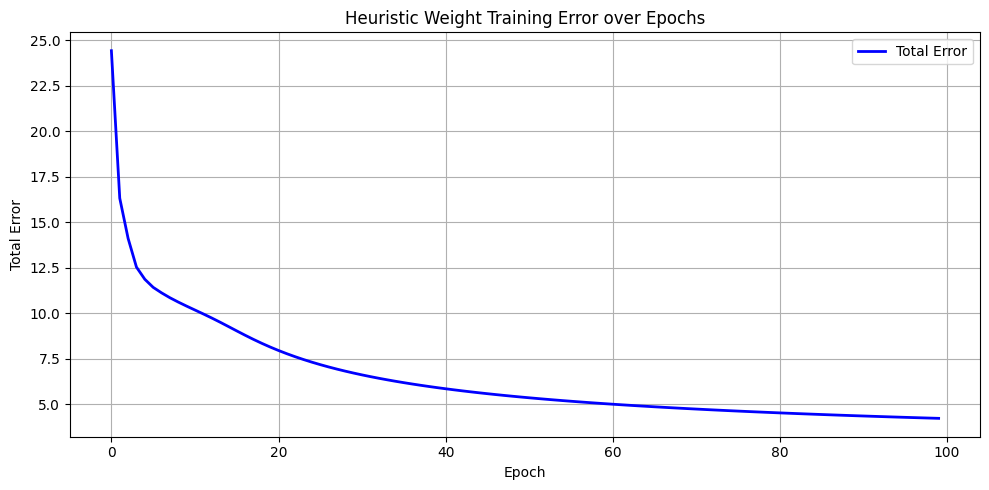

In [24]:
plt.figure(figsize=(10, 5))
plt.plot(h_epoch, heuristic_total_error, label="Total Error", color="blue", linewidth=2)

plt.title("Heuristic Weight Training Error over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Total Error")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
# Apple feature vector
test_apple = np.array([0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1])

# Calculate prediction using the trained weights
prediction_heuristic = sigmoid(np.dot(test_apple, heuristic_weights))

print("Prediction probabilities for apple input:")
print(prediction_heuristic)

print("Output 1: %.4f, Output 2: %.4f" % (prediction_heuristic[0], prediction_heuristic[1]))

Prediction probabilities for apple input:
[9.99332117e-01 6.30843567e-04]
Output 1: 0.9993, Output 2: 0.0006


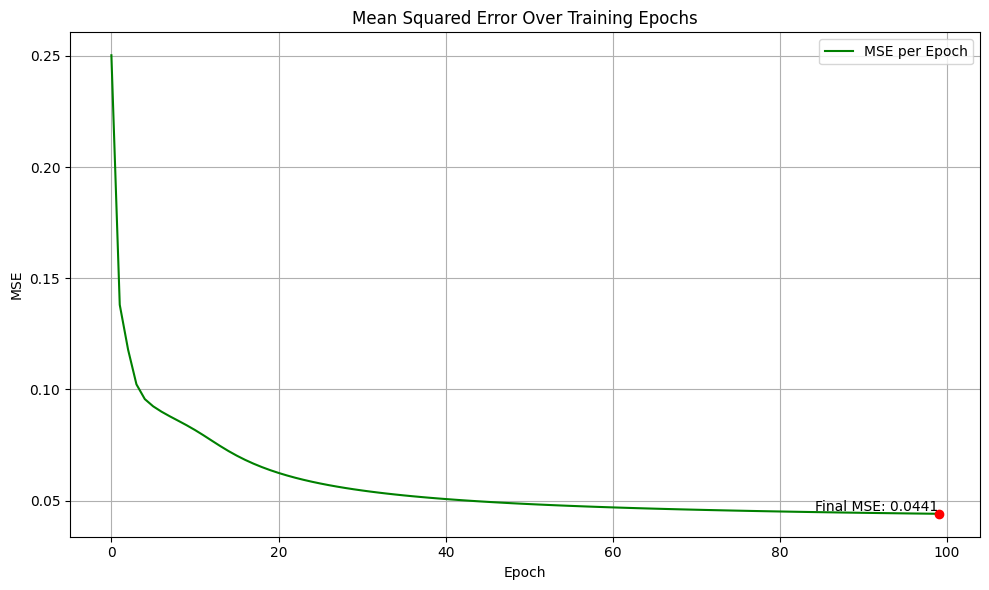

In [26]:
plt.figure(figsize=(10, 6))
plt.plot(h_epoch, heuristic_mse_history, label='MSE per Epoch', color='green')

# Highlight the final MSE
plt.scatter(h_epoch[-1], heuristic_mse_history[-1], color='red', zorder=5)
plt.text(h_epoch[-1], heuristic_mse_history[-1], f'Final MSE: {heuristic_mse_history[-1]:.4f}',
         verticalalignment='bottom', horizontalalignment='right')

plt.title('Mean Squared Error Over Training Epochs')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Generic Weight

In [27]:
generic_weights = 7 * np.random.random((n_features, n_outputs)) - 1
print(generic_weights)

[[ 3.82966855  1.74435087]
 [ 5.68989082  5.0370313 ]
 [-0.03513084  3.23860114]
 [ 5.33369118 -0.63591886]
 [-0.17530355  3.16600797]
 [ 4.28950881  2.13513553]
 [ 0.35088354 -0.58666129]
 [ 4.77338893  2.95219736]
 [ 2.87071899  4.43785421]
 [-0.73705065  2.09931222]
 [ 5.75273701 -0.19302449]
 [ 1.51313801 -0.11584858]
 [ 3.96002502  1.29395395]]


In [28]:
# Train using the reusable function
generic_weights, g_epoch, generic_total_error, generic_mse_history = train_weights(training_inputs, training_outputs, generic_weights, epochs=100)

# After training
print("Trained weights after training:")
print(generic_weights)

Trained weights after training:
[[ 3.45166045  2.71569331]
 [ 5.68988997  3.89354223]
 [ 0.66257076 -1.04170217]
 [ 5.33324008 -3.22833254]
 [-0.20840858 -1.3729781 ]
 [ 4.28975798 -1.87713009]
 [ 0.70308452  3.12909878]
 [ 4.77328536  0.74282534]
 [ 2.86934207  0.00701834]
 [-0.41643217 -0.51471555]
 [ 5.71942495  2.54365749]
 [ 1.8662248  -3.50605084]
 [ 3.95949185 -5.0973894 ]]


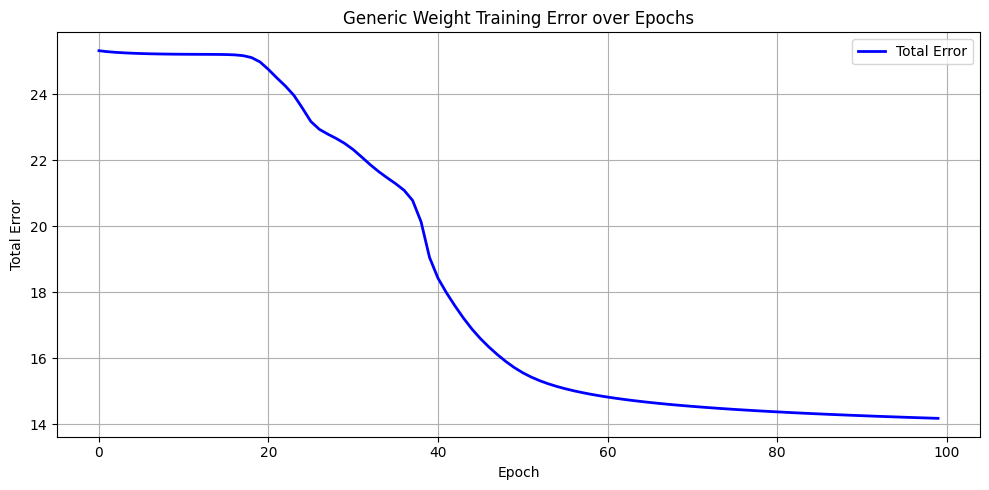

In [29]:
plt.figure(figsize=(10, 5))
plt.plot(g_epoch, generic_total_error, label="Total Error", color="blue", linewidth=2)

plt.title("Generic Weight Training Error over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Total Error")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
# Apple feature vector
test_apple = np.array([0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1])

# Calculate prediction using the trained weights
prediction_generic = sigmoid(np.dot(test_apple, generic_weights))

print("Prediction probabilities for apple input:")
print(prediction_generic)

print("Output 1: %.4f, Output 2: %.4f" % (prediction_generic[0], prediction_generic[1]))

Prediction probabilities for apple input:
[9.99795633e-01 1.97231094e-04]
Output 1: 0.9998, Output 2: 0.0002


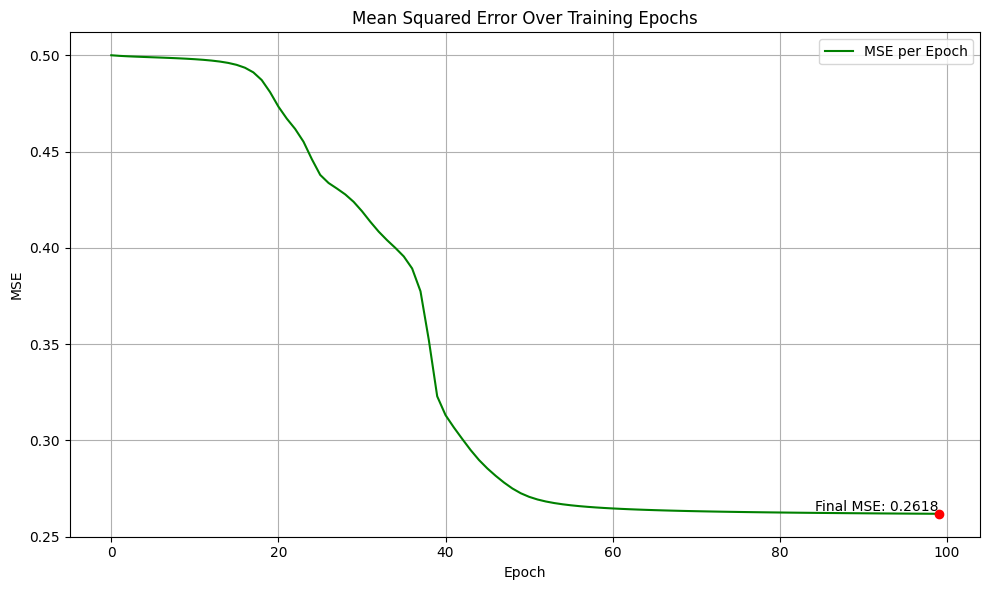

In [31]:
plt.figure(figsize=(10, 6))
plt.plot(g_epoch, generic_mse_history, label='MSE per Epoch', color='green')

# Highlight the final MSE
plt.scatter(g_epoch[-1], generic_mse_history[-1], color='red', zorder=5)
plt.text(g_epoch[-1], generic_mse_history[-1], f'Final MSE: {generic_mse_history[-1]:.4f}',
         verticalalignment='bottom', horizontalalignment='right')

plt.title('Mean Squared Error Over Training Epochs')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Comparison

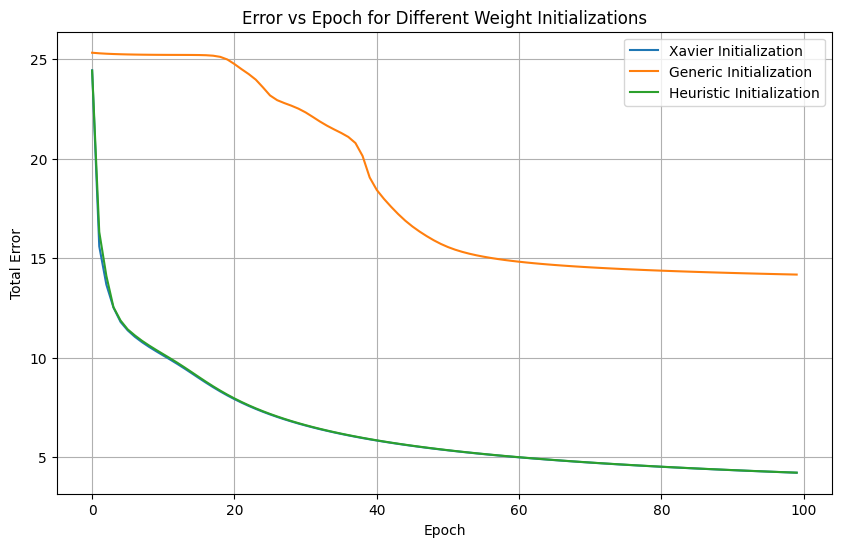

In [32]:
# Plot errors
plt.figure(figsize=(10, 6))
plt.plot(x_epoch, xavier_total_error, label='Xavier Initialization')
plt.plot(g_epoch, generic_total_error, label='Generic Initialization')
plt.plot(h_epoch, heuristic_total_error, label='Heuristic Initialization')
plt.xlabel('Epoch')
plt.ylabel('Total Error')
plt.title('Error vs Epoch for Different Weight Initializations')
plt.legend()
plt.grid(True)
plt.show()

# More Testing

In [33]:
import numpy as np

test_inputs = np.array([
    [0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1],  # Apple
    [1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0],  # Mango
    [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0],  # Carrot
    [1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1],  # Banana
    [0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0],  # Tomato
    [1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0],  # Orange
    [0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0],  # Lettuce
    [1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1],  # Pineapple
    [0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0],  # Cucumber
    [1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1],  # Grapes
])

true_labels = np.array([
    [1, 0],  # Apple
    [1, 0],  # Mango
    [0, 1],  # Carrot
    [1, 0],  # Banana
    [1, 0],  # Tomato
    [1, 0],  # Orange
    [0, 1],  # Lettuce
    [1, 0],  # Pineapple
    [1, 0],  # Cucumber
    [1, 0],  # Grapes
])


In [34]:
def get_predicted_labels(predictions):
    return np.argmax(predictions, axis=1)

def calculate_accuracy(predictions, true_labels):
    pred_labels = get_predicted_labels(predictions)
    true_labels_cls = np.argmax(true_labels, axis=1)
    accuracy = np.sum(pred_labels == true_labels_cls) / len(true_labels_cls)
    return accuracy

In [35]:
predictions_xavier = []
predictions_generic = []
predictions_heuristic = []

for test_vector in test_inputs:
    predictions_xavier.append(sigmoid(np.dot(test_vector, xavier_weights)))
    predictions_generic.append(sigmoid(np.dot(test_vector, generic_weights)))
    predictions_heuristic.append(sigmoid(np.dot(test_vector, heuristic_weights)))

predictions_xavier = np.array(predictions_xavier)
predictions_generic = np.array(predictions_generic)
predictions_heuristic = np.array(predictions_heuristic)

accuracy_xavier = calculate_accuracy(predictions_xavier, true_labels)
accuracy_generic = calculate_accuracy(predictions_generic, true_labels)
accuracy_heuristic = calculate_accuracy(predictions_heuristic, true_labels)

print(f"Accuracy of Xavier Initialization Model: {accuracy_xavier * 100:.2f}%")
print(f"Accuracy of Generic Initialization Model: {accuracy_generic * 100:.2f}%")
print(f"Accuracy of Heuristic Initialization Model: {accuracy_heuristic * 100:.2f}%")

Accuracy of Xavier Initialization Model: 80.00%
Accuracy of Generic Initialization Model: 80.00%
Accuracy of Heuristic Initialization Model: 80.00%
